In [1]:
from argparse import ArgumentParser, Namespace
import Spectral_Preprocessing as sp
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import json

In [2]:
parser = ArgumentParser()
parser.add_argument("--range-ir-1", dest= "wn_range_ir_1", default = (948,1860))
parser.add_argument("--range-ir-2", dest= "wn_range_ir_2", default = (2698,3002))

parser.add_argument("--range-min-ir", dest= "range_min_ir", type = int, default = 400)
parser.add_argument("--range-max-ir", dest= "range_max_ir", type = int, default = 4000)
parser.add_argument("--interpolate-interval-ir", dest = "interpolate_interval_ir", type = int, default = 1) 

parser.add_argument("--finger-print-exl", dest= "finger_print_exl", type = bool, default = False)
parser.add_argument("--trans-chip", dest= "trans_chip", type = bool, default = False)

parser.add_argument("--background-rule-ir", dest= "background_rule", type = str, default = 'mean')
parser.add_argument("--threshold-mean-intensity-ir", dest= "ths_mean_int_ir", type = float, default = 0)
parser.add_argument("--threshold-total-variation-intensity-ir", dest= "ths_tot_var_int_ir", type = float, default = 0)

parser.add_argument("--range-min-raman", dest= "range_min_raman", type = float, default = 400)
parser.add_argument("--range-max-raman", dest= "range_max_raman", type = float, default = 4000)
parser.add_argument("--interpolate-interval-raman", dest = "interpolate_interval_raman", type = float, default = 1) 

parser.add_argument("--rubberband", dest="rubberband", action="store_true", default=False,)
parser.add_argument("--minmax", dest="minmax", action="store_true", default=False,)
parser.add_argument("--no-interpolate", dest = "no_interpolate", action="store_true", default = False)
parser.add_argument("--nitrogen-calibration", dest="nitrogen_calibration", action="store_true", default=True,)
parser.add_argument("--si-peak", dest= "si_peak", type = float, default = 520)

parser.add_argument("--smooth", dest = "smooth", type = int, default = 0)
parser.add_argument("--baseline", dest = "baseline", type = int, default = 5)

###Sample Code #1: Specify IR and Raman interpolation intervals along with min & max values
args: Namespace = parser.parse_args([]) ###Do not alter this section.
###PLEASE TYPE IN YOUR ARGUMENTS HERE
args.wn_range_ir_1 = (980, 1800) #(675.0,1800)
args.wn_range_ir_2 = (2720, 2970) #(1800,4000)
args.range_min_ir = 675.0 #674.9918 ###enter an integer
args.range_max_ir = 4000.0 #3999.809 ###enter an integer [max value is not included]
args.interpolate_interval_ir = 2 #1.929 ###enter an integer
args.finger_print_exl = False
args.trans_chip = True
args.background_rule = 'total_var'
args.ths_mean_int_ir = 0.043
args.ths_tot_var_int_ir = 0.4543#0.59

args.range_min_raman = 355 #.555542 ###enter an integer or float #530
args.range_max_raman = 3500 #3895.935059 ##enter an integer or float [max value is not included] 
args.interpolate_interval_raman = 2.0 #168021680216802 ###enter an integer or float

args.rubberband = 'none'#'specy' ###True for rubberband, False for iModPoly
args.minmax = 'snv' ###False for SVT normalization, True for minmax
args.no_interpolate = False ###use sample code 2 if using True for this option.
args.nitrogen_calibration = True ##True for calibration, False for no calibration.
args.si_peak = 520 ###enter an integer or float

In [3]:
directory_name = 'pilot_phase_raw_data/' ###directory where the PTIR files will be downloaded from.
ir_export_filename =  "no_interpolate_equiv_ir.csv"  ###enter your desired export Raman csv filename, in quotes
raman_export_filename =  "no_interpolate_equiv_raman.csv"  ###enter your desired export Raman csv filename, in quotes
file_list_tmp = [] ###option to list out the files you want included. if left as-is, all files in directory will be i

path = 'pilot_phase_raw_data'
files_list = os.listdir(path)

files_ignores = [
    'MEC_02_083_DC_AlSI_2_051023_06072023_Run3.ptir',
    'MEC_02_078_FHS_AlSI_2_051023_06072023_Run1.ptir',
    'MEC_02_083_DC_AlSI_2_051023_06072023_Run2.ptir',
    'MEC_02_078_FHS_AlSI_2_051023_06072023_Run2.ptir',
    'MEC_02_066_Daycroft_AlSI_1_051023_06072023_Run3.ptir'
]

#files_list = [x for x in files_list if x not in files_ignores]
files_list = files_ignores

In [4]:
args.si_peak = [520]*len(files_list)
(raman_final, 
 ir_final, 
 label_list, 
 XX_ir, 
 XX_raman, 
 ids, 
 coords, 
 _, 
 rng, 
 ir_bg_label, 
 saturated_wn_list) = sp.ptir_to_interpolated_processed_csv(
        args, directory_name,
        ir_export_filename, raman_export_filename,                                                     
        file_list = files_list, transpose = True)

Row Mismatch pilot_phase_raw_data/MEC_02_083_DC_AlSI_2_051023_06072023_Run3.ptir


/Users/eochoa/Documents/Research_Ambuj/M4AM/spectral_libraries/Spectral_Preprocessing.py:187: RuntimeWarning: invalid value encountered in divide
  return (x - x.mean()) / x.std()


Row Mismatch pilot_phase_raw_data/MEC_02_078_FHS_AlSI_2_051023_06072023_Run1.ptir
NA Rows Removed but no other issues pilot_phase_raw_data/MEC_02_078_FHS_AlSI_2_051023_06072023_Run1.ptir


/Users/eochoa/Documents/Research_Ambuj/M4AM/spectral_libraries/Spectral_Preprocessing.py:187: RuntimeWarning: invalid value encountered in divide
  return (x - x.mean()) / x.std()


Row Mismatch pilot_phase_raw_data/MEC_02_083_DC_AlSI_2_051023_06072023_Run2.ptir


/Users/eochoa/Documents/Research_Ambuj/M4AM/spectral_libraries/Spectral_Preprocessing.py:187: RuntimeWarning: invalid value encountered in divide
  return (x - x.mean()) / x.std()


Row Mismatch pilot_phase_raw_data/MEC_02_078_FHS_AlSI_2_051023_06072023_Run2.ptir


/Users/eochoa/Documents/Research_Ambuj/M4AM/spectral_libraries/Spectral_Preprocessing.py:187: RuntimeWarning: invalid value encountered in divide
  return (x - x.mean()) / x.std()


Row Mismatch pilot_phase_raw_data/MEC_02_066_Daycroft_AlSI_1_051023_06072023_Run3.ptir


/Users/eochoa/Documents/Research_Ambuj/M4AM/spectral_libraries/Spectral_Preprocessing.py:187: RuntimeWarning: invalid value encountered in divide
  return (x - x.mean()) / x.std()


In [39]:
n_spec = 0
for f in files_list:
    #if f in file_ignored:
    #    continue
    print(f)
    
    ir_data, ir_coords, ir_labels = sp.ptir_studio_to_csv('pilot_phase_raw_data/'+f, 
                                                          'IR')
    
    n_spec = n_spec + ir_coords.shape[0]
n_spec

MEC_02_083_DC_AlSI_2_051023_06072023_Run3.ptir
MEC_02_074_IAO_AlSI_1_04261023_05252023_Run2.ptir
MEC_02_074_IAO_AlSI_2_04261023_05252023_Run1.ptir
MEC_02_066_Daycroft_AlSI_1_051023_06072023_Run1.ptir
MEC_02_078_FHS_AlSI_2_051023_06072023_Run1.ptir
MEC_02_072_ICB_AlSI_1_054261023_05252023_Run1.ptir
MEC_02_074_IAO_AlSI_1_04261023_05252023_Run3.ptir
MEC_02_083_DC_AlSI_2_051023_06072023_Run2.ptir
MEC_02_082_ICB_AlSI_2_04261023_05252023_Run2.ptir
MEC_02_068_FHS_AlSI_1_051023_06072023_Run3.ptir
MEC_02_068_FHS_AlSI_1_051023_06072023_Run2.ptir
MEC_02_082_ICB_AlSI_2_04261023_05252023_Run3.ptir
MEC_02_068_FHS_AlSI_1_051023_06072023_Run1.ptir
MEC_02_083_DC_AlSI_2_051023_06072023_Run2_redo_100particles.ptir
MEC_02_082_ICB_AlSI_2_04261023_05252023_Run1.ptir
MEC_02_074_IAO_AlSI_2_04261023_05252023_Run3.ptir
MEC_02_072_ICB_AlSI_1_054261023_05252023_Run2.ptir
MEC_02_066_Daycroft_AlSI_1_051023_06072023_Run2.ptir
MEC_02_078_FHS_AlSI_2_051023_06072023_Run2.ptir
MEC_02_078_FHS_AlSI_2_051023_06072023_Run3.

2653

In [40]:
n_spec = 0
for f in files_list:
    #if f in file_ignored:
    #    continue
    print(f)
    
    raman_data, raman_coords, raman_labels = sp.ptir_studio_to_csv('pilot_phase_raw_data/'+f, 
                                                          'Raman')
    
    n_spec = n_spec + raman_data.shape[0]
n_spec

MEC_02_083_DC_AlSI_2_051023_06072023_Run3.ptir
MEC_02_074_IAO_AlSI_1_04261023_05252023_Run2.ptir
MEC_02_074_IAO_AlSI_2_04261023_05252023_Run1.ptir
MEC_02_066_Daycroft_AlSI_1_051023_06072023_Run1.ptir
MEC_02_078_FHS_AlSI_2_051023_06072023_Run1.ptir
MEC_02_072_ICB_AlSI_1_054261023_05252023_Run1.ptir
MEC_02_074_IAO_AlSI_1_04261023_05252023_Run3.ptir
MEC_02_083_DC_AlSI_2_051023_06072023_Run2.ptir
MEC_02_082_ICB_AlSI_2_04261023_05252023_Run2.ptir
MEC_02_068_FHS_AlSI_1_051023_06072023_Run3.ptir
MEC_02_068_FHS_AlSI_1_051023_06072023_Run2.ptir
MEC_02_082_ICB_AlSI_2_04261023_05252023_Run3.ptir
MEC_02_068_FHS_AlSI_1_051023_06072023_Run1.ptir
MEC_02_083_DC_AlSI_2_051023_06072023_Run2_redo_100particles.ptir
MEC_02_082_ICB_AlSI_2_04261023_05252023_Run1.ptir
MEC_02_074_IAO_AlSI_2_04261023_05252023_Run3.ptir
MEC_02_072_ICB_AlSI_1_054261023_05252023_Run2.ptir
MEC_02_066_Daycroft_AlSI_1_051023_06072023_Run2.ptir
MEC_02_078_FHS_AlSI_2_051023_06072023_Run2.ptir
MEC_02_078_FHS_AlSI_2_051023_06072023_Run3.

2658

In [ ]:
2653, 2658

In [76]:
#ir_data, ir_coords, ir_labels
#raman_data, raman_coords, raman_labels

ir_data.drop([103, 104])

,948.0,950.0,952.0,954.0,956.0,958.0,960.0,962.0,964.0,966.0,...,2984.0,2986.0,2988.0,2990.0,2992.0,2994.0,2996.0,2998.0,3000.0,3002.0
0,-11.567978,-8.489072,-1.152350,0.708794,-3.288227,-1.589775,-3.776421,-2.346167,-0.045465,-0.148116,...,-7.293011,-3.811683,-2.758303,-7.157756,-5.526591,-5.351269,-4.513754,-8.751558,-17.964540,-16.539026
1,2.415524,2.161042,3.101432,-0.131648,0.010973,-0.785929,0.264765,-1.982063,-0.789396,-1.298462,...,-2.557798,0.482766,4.133369,4.845397,1.496127,-3.002814,-5.056242,-1.054667,-6.503963,-1.948584
2,2.091296,2.576621,0.202698,-0.773197,-0.846646,0.788147,-0.331404,0.048088,-0.027565,0.135584,...,-1.446592,-1.225524,-1.397169,-1.411703,0.552120,0.595618,-0.367995,0.446687,-1.099244,-0.050441
3,4.540631,7.128633,4.997062,6.546412,7.430984,5.325127,6.093488,6.774708,7.569579,8.311155,...,3.684598,3.047582,0.764034,0.428371,1.811893,-0.181741,-0.659091,-1.417886,-0.333559,-0.454761
4,-0.151963,-0.556952,1.351564,1.923421,3.067961,3.989200,4.627495,4.603645,5.063306,5.714118,...,-1.406797,-1.293814,-2.675051,-0.867728,-0.828948,-0.590362,-0.614188,-2.350212,-4.838210,-3.433135
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
98,-4.926239,1.163268,0.742247,1.654519,0.665382,-0.782737,-1.262587,0.045642,0.587113,0.812014,...,2.997679,6.455265,4.879445,-0.486145,0.607550,-1.074104,1.490226,-0.615244,2.165908,0.422423
99,1.386073,0.348704,0.561041,-0.264813,0.668342,1.365493,2.157665,2.411791,1.529560,0.713087,...,2.906976,1.068541,3.100483,3.389274,2.718626,1.952811,0.915924,-1.134794,2.860425,-2.318740
100,-8.485767,-10.119170,-10.753818,-7.154977,-4.617348,-3.125706,-5.209638,-3.464752,-0.945411,-0.981706,...,0.142628,-6.808293,-4.751149,-6.333365,-5.881944,-0.220121,-5.944952,-3.546000,-9.305272,-17.123383
101,-14.574556,-5.114170,-3.394352,-3.148886,-4.357047,-6.356638,-8.874165,-0.859643,1.607199,1.009902,...,0.537633,-7.573123,1.447931,-0.393054,-12.412875,-6.158367,-16.673269,-8.273129,-29.378960,-12.659717


In [11]:
raman_final.shape

(2651, 1573)

In [30]:
ir_final.shape

(2177, 535)

In [5]:
school = np.array(["DC" if (x).split("_")[3] == "Daycroft" else (x).split("_")[3] for x in ids])

ids_file_name = np.array([x[:-5] for x in ids])

ids_file_name = ids_file_name.astype('<U70')
ids_file_name_list = np.unique(ids_file_name)

idx_ = []
i = 1
for j, x in enumerate(ids_file_name):
    #idx_.append(i)
    ids_file_name[j] = x +'_'+ str(i)
    if j < ids_file_name.shape[0]-1 and x != ids_file_name[j+1]:
        i = 1
    else:
        i = i + 1
        
ids_file_name

array(['MEC_02_083_DC_AlSI_2_051023_06072023_Run3_1',
       'MEC_02_083_DC_AlSI_2_051023_06072023_Run3_2',
       'MEC_02_083_DC_AlSI_2_051023_06072023_Run3_3',
       'MEC_02_083_DC_AlSI_2_051023_06072023_Run3_4',
       'MEC_02_083_DC_AlSI_2_051023_06072023_Run3_5',
       'MEC_02_083_DC_AlSI_2_051023_06072023_Run3_6',
       'MEC_02_083_DC_AlSI_2_051023_06072023_Run3_7',
       'MEC_02_083_DC_AlSI_2_051023_06072023_Run3_8',
       'MEC_02_083_DC_AlSI_2_051023_06072023_Run3_9',
       'MEC_02_083_DC_AlSI_2_051023_06072023_Run3_10',
       'MEC_02_083_DC_AlSI_2_051023_06072023_Run3_11',
       'MEC_02_083_DC_AlSI_2_051023_06072023_Run3_12',
       'MEC_02_083_DC_AlSI_2_051023_06072023_Run3_13',
       'MEC_02_083_DC_AlSI_2_051023_06072023_Run3_14',
       'MEC_02_083_DC_AlSI_2_051023_06072023_Run3_15',
       'MEC_02_083_DC_AlSI_2_051023_06072023_Run3_16',
       'MEC_02_083_DC_AlSI_2_051023_06072023_Run3_17',
       'MEC_02_083_DC_AlSI_2_051023_06072023_Run3_18',
       'MEC_02_083_

In [6]:
nas_list = np.unique(np.where(np.isnan(raman_final))[0])
non_nas_idx = [x not in nas_list for x in range(raman_final.shape[0])]

saturated_wn_dict = {id_:str(list(x))[1:-1] for x, id_ in zip(saturated_wn_list,ids_file_name) if x.shape[0]>0}
saturated_wn_dict
#with open('gloves_contamination/pilot_phase_data_raman_saturation_new_data.json', 'w') as f:
#    json.dump(saturated_wn_dict, f)

{'MEC_02_083_DC_AlSI_2_051023_06072023_Run3_3': '0, 1, 2',
 'MEC_02_083_DC_AlSI_2_051023_06072023_Run3_4': '0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 20

In [7]:
sum(~np.array(non_nas_idx))

43

In [8]:
preposs_data_ir = pd.DataFrame(ir_final)
preposs_data_ir.columns = XX_ir
preposs_data_ir = pd.concat([preposs_data_ir, coords], axis=1)
preposs_data_ir['id'] = ids_file_name
preposs_data_ir['background'] = ir_bg_label
preposs_data_ir['school'] = school
preposs_data_ir = preposs_data_ir.loc[non_nas_idx, :].reset_index(drop=True)

#preposs_data_ir.to_csv('gloves_contamination/pilot_phase_data_ir_final.csv')

preposs_data_raman = pd.DataFrame(raman_final)
preposs_data_raman.columns = XX_raman
preposs_data_raman = pd.concat([preposs_data_raman, coords], axis=1)
preposs_data_raman['id'] = ids_file_name
preposs_data_raman['school'] = school
preposs_data_raman = preposs_data_raman.loc[np.array(non_nas_idx), :].reset_index(drop=True)
preposs_data_raman.to_csv('gloves_contamination/pilot_phase_data_raman_final_no_baseline_correctionspecy_new_data.csv')

In [14]:
pilot_phase_data_raman_res_new_data = pd.read_csv('gloves_contamination/pilot_phase_data_raman_res_new_data.csv')
del pilot_phase_data_raman_res_new_data['Unnamed: 0']
res_new_data_ids = list(pilot_phase_data_raman_res_new_data['id'])

In [16]:
preposs_data_raman.query('id in @res_new_data_ids').to_csv('gloves_contamination/pilot_phase_data_raman_final_no_baseline_correctionspecy_new_data.csv')

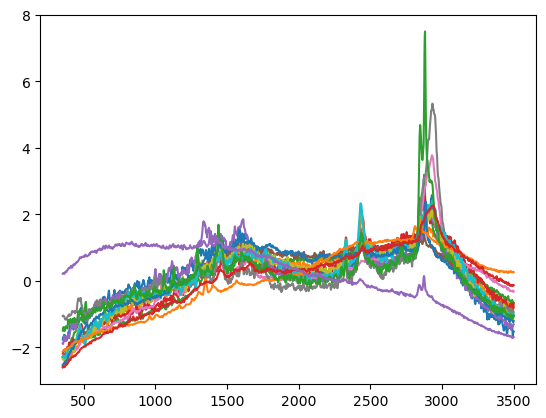

In [20]:
_ = plt.plot(preposs_data_raman.query('id in @res_new_data_ids').iloc[:,:-4].T)